In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

In [ ]:
df = pd.read_csv("winequality-red.csv", sep=";")

print(df.shape)              
print(df.isnull().sum())     
df.head()                   

(1599, 12)
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [32]:
print(df["quality"].value_counts().sort_index())

quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


In [ ]:
def classificador(nota):
    if nota <= 5:
        return "ruim"
    elif nota <= 7:
        return "medio"
    else:
        return "bom"

df["classe"] = df["quality"].apply(classificador)
print(df["classe"].value_counts())

classe
medio    837
ruim     744
bom       18
Name: count, dtype: int64


In [ ]:
X = df.drop(columns=["quality", "classe"])   
y = df["classe"]                           

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y        
)

print("Treino:", X_train.shape[0], "amostras")
print("Teste: ", X_test.shape[0], "amostras")
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

Treino: 1279 amostras
Teste:  320 amostras
classe
medio    0.523847
ruim     0.465207
bom      0.010946
Name: proportion, dtype: float64
classe
medio    0.521875
ruim     0.465625
bom      0.012500
Name: proportion, dtype: float64


In [ ]:
scaler = StandardScaler()                        
X_train_norm = scaler.fit_transform(X_train)     
X_test_norm = scaler.transform(X_test)           

In [39]:
valores_k = [1, 3, 5, 7, 11]
acuracias_medias = []

for k in valores_k:
    modelo = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(modelo, X_train_norm, y_train, cv=5, scoring="accuracy")
    acuracias_medias.append(scores.mean())
    print(f"k = {k:2d} -> acurácia média = {scores.mean():.4f}")

k =  1 -> acurácia média = 0.7209
k =  3 -> acurácia média = 0.6685
k =  5 -> acurácia média = 0.6794
k =  7 -> acurácia média = 0.6974
k = 11 -> acurácia média = 0.7123


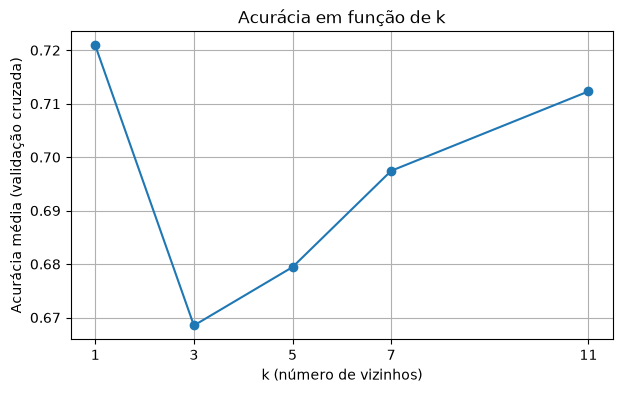

In [ ]:
plt.figure(figsize=(7, 4))
plt.plot(valores_k, acuracias_medias, marker="o")
plt.xlabel("k (número de vizinhos)")
plt.ylabel("Acurácia média (validação cruzada)")
plt.title("Acurácia em função de k")
plt.xticks(valores_k)
plt.grid(True)
plt.savefig("acuracia_vs_k.png", dpi=150)  
plt.show()

In [41]:
melhor_k = valores_k[int(np.argmax(acuracias_medias))]
print("Melhor k:", melhor_k)

Melhor k: 1


In [42]:
modelo_final = KNeighborsClassifier(n_neighbors=melhor_k)
modelo_final.fit(X_train_norm, y_train)

y_pred = modelo_final.predict(X_test_norm)

[[112  37   0]
 [ 33 133   1]
 [  0   4   0]]


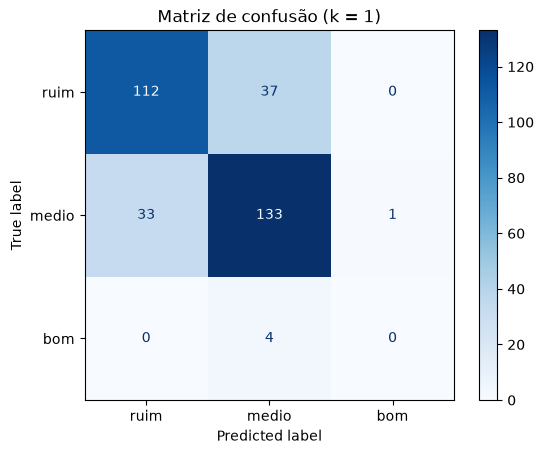

In [43]:
ordem = ["ruim", "medio", "bom"]

cm = confusion_matrix(y_test, y_pred, labels=ordem)
print(cm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=ordem)
disp.plot(cmap="Blues")
plt.title(f"Matriz de confusão (k = {melhor_k})")
plt.savefig("matriz_confusao.png", dpi=150)
plt.show()

In [44]:
print(classification_report(y_test, y_pred, labels=ordem, zero_division=0))

              precision    recall  f1-score   support

        ruim       0.77      0.75      0.76       149
       medio       0.76      0.80      0.78       167
         bom       0.00      0.00      0.00         4

    accuracy                           0.77       320
   macro avg       0.51      0.52      0.51       320
weighted avg       0.76      0.77      0.76       320

